In [ ]:
'''Classify the email using the binary classification method. Email Spam detection has two 
states: a) Normal State – Not Spam, b) Abnormal State – Spam. Use K-Nearest Neighbors and 
Support Vector Machine for classification. Analyze their performance. 
Dataset link: The emails.csv dataset on the Kaggle 
https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv'''

In [3]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [4]:
# 2. Load dataset
df = pd.read_csv("emails.csv")

print("Dataset:")
print(df.head())

print("Shape:", df.shape)

Dataset:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
Shape: (5172, 3002)


In [5]:
# 3. Preprocess dataset
df = df.dropna()

# Separate features and target
X = df.iloc[:, 1:-1]     # Remove email ID
y = df.iloc[:, -1]       # Last column is Prediction

In [6]:
# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. KNN Classification
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

# 7. SVM Classification
svm = SVC(kernel="linear")

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

In [9]:
# 8. Evaluate models
def evaluate_model(name, y_test, predictions):

    print("\n", name)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, predictions)
    print(cm)

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


 KNN Classifier
Accuracy: 0.8338164251207729

Confusion Matrix:
[[576 159]
 [ 13 287]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



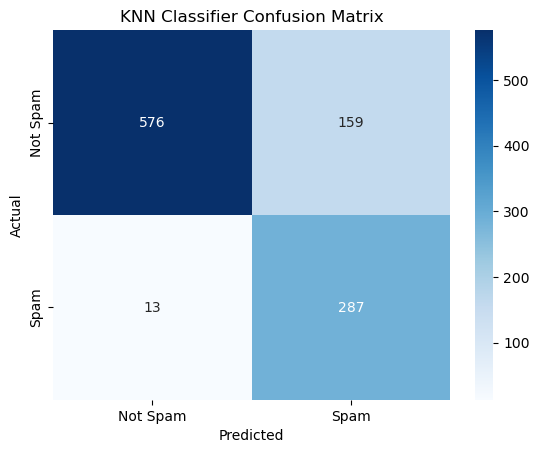


 SVM Classifier
Accuracy: 0.9507246376811594

Confusion Matrix:
[[709  26]
 [ 25 275]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



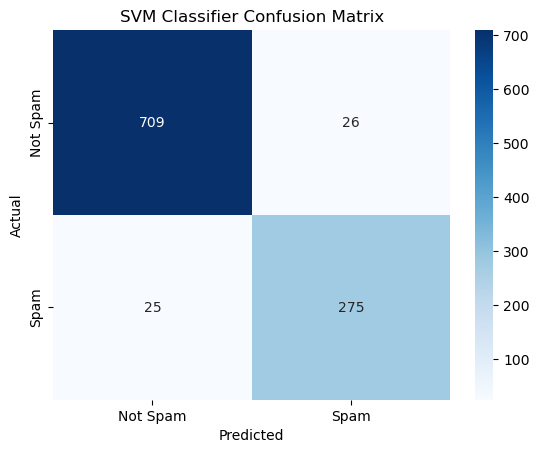

In [8]:
# 9. Compare both models
evaluate_model("KNN Classifier", y_test, knn_pred)

evaluate_model("SVM Classifier", y_test, svm_pred)